# Problema 5 — Segmentação de clientes com k-Means

## Tarefa 1 — Preparação dos gastos

O k-Means usa apenas as seis categorias de gastos. Reservamos `Channel` e `Region` para comparação externa.

A tabela descritiva reúne média, mediana (linha 50%), desvio padrão, mínimo e máximo. O boxplot mostra a assimetria e os valores extremos antes da transformação.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from sklearn.decomposition import PCA

# Configurações visuais elegantes
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 12

In [2]:
df = pd.read_csv("data/Wholesale customers data.csv")
print("Dimensões do Dataset:", df.shape)
df.head()

Dimensões do Dataset: (440, 8)


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [3]:
# Isolamento das variáveis contínuas de gastos
features_gasto = ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']

X_gastos = df[features_gasto].copy()
meta_info = df[['Channel', 'Region']].copy()

print("Verificação de valores ausentes:")
print(df.isnull().sum())

Verificação de valores ausentes:
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64


In [4]:
X_gastos.describe()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


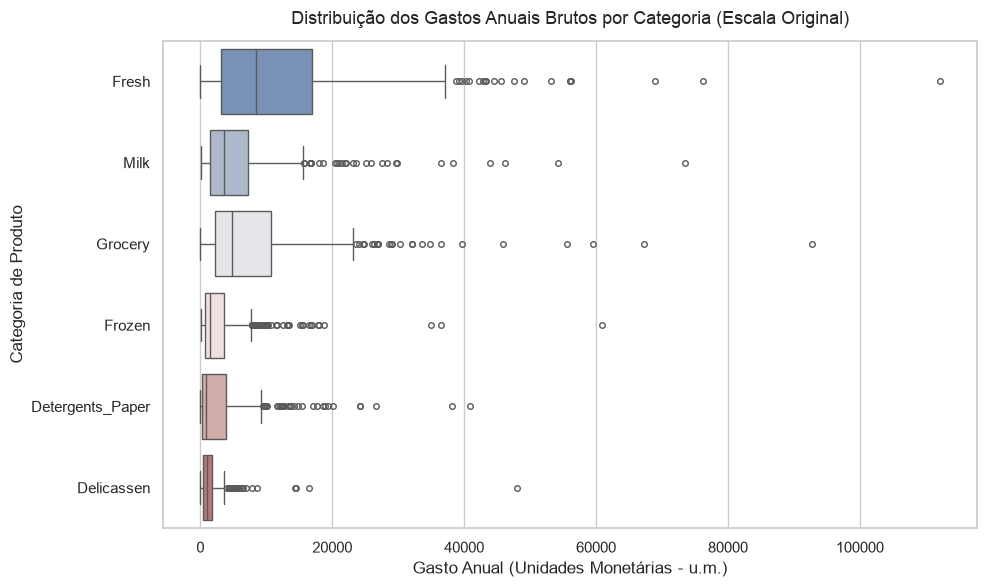

In [5]:
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=X_gastos,
    orient="h",
    palette="vlag",
    fliersize=4
)
plt.title("Distribuição dos Gastos Anuais Brutos por Categoria (Escala Original)", fontsize=13, pad=12)
plt.xlabel("Gasto Anual (Unidades Monetárias - u.m.)", fontsize=12)
plt.ylabel("Categoria de Produto", fontsize=12)
plt.tight_layout()
plt.show()

In [6]:
# 1. Transformação logarítmica
X_log = np.log1p(X_gastos)

# 2. Padronização Z-score
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)
X_scaled_df = pd.DataFrame(X_scaled, columns=features_gasto)

print("Médias pós-padronização (esperado ~0):\n", np.round(X_scaled.mean(axis=0), 2))
print("\nDesvios padrão pós-padronização (esperado 1):\n", np.round(X_scaled.std(axis=0), 2))

Médias pós-padronização (esperado ~0):
 [ 0. -0. -0.  0. -0. -0.]

Desvios padrão pós-padronização (esperado 1):
 [1. 1. 1. 1. 1. 1.]


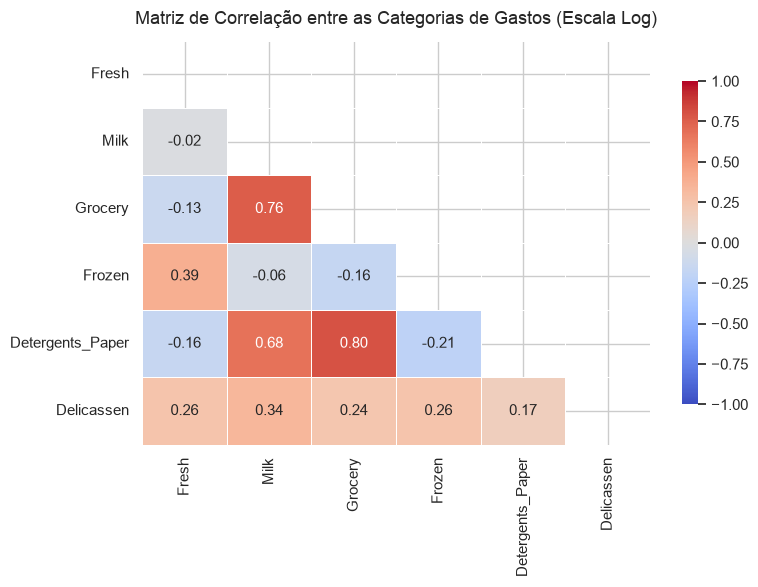

In [7]:
corr_gastos = X_log.corr()

mask = np.triu(np.ones_like(corr_gastos, dtype=bool))

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_gastos,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    vmin=-1, vmax=1,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)
plt.title("Matriz de Correlação entre as Categorias de Gastos (Escala Log)", fontsize=13, pad=12)
plt.tight_layout()
plt.show()

### Distribuição e pré-processamento

As seis categorias têm **média acima da mediana**, indicando assimetria à direita. Em Fresh, por exemplo, os gastos vão de **3 a 112.151**.

| Etapa | Por que é utilizada |
|---|---|
| `log1p(x)` | Comprime gastos altos e reduz sua influência relativa, sem excluir clientes. |
| Z-score | Equilibra as escalas das categorias para que nenhuma domine a distância euclidiana apenas pela magnitude dos valores. |

### Grocery e Detergents_Paper

A correlação é forte e positiva: **r = 0,797 após log1p** (aproximadamente 0,925 nos dados brutos).

Clientes que gastam mais em mercearia também tendem a gastar mais em detergentes e papel. Isso é compatível com um perfil de compras conjunto, sem indicar causalidade entre as categorias.

A padronização não remove a correlação entre categorias. Grocery e Detergents_Paper continuam carregando informações semelhantes, de modo que esse padrão de compra participa da distância por duas entradas.


## Tarefa 2 — Ausência de divisão treino/teste

O objetivo deste exercício é descrever os perfis de compra dos 440 clientes disponíveis.

| Tipo de aprendizado | Objetivo da avaliação |
|---|---|
| Supervisionado | Estimar o erro de previsão em dados de teste com rótulos conhecidos. |
| Agrupamento neste projeto | Avaliar se os grupos encontrados são coesos, separados e comercialmente interpretáveis. |

**Não fazemos a divisão 80/20 neste exercício**, pois buscamos uma partição descritiva de toda a base.

O desafio é avaliar a qualidade sem um gabarito de segmentos. Combinamos silhueta, interpretação dos gastos e comparação externa com Channel e Region. A ausência de rótulos não impede outros estudos de estabilidade ou validação em novas amostras.

## Tarefa 3 — Número de grupos

Testamos k de **2 a 10**. A inércia mede a soma das distâncias quadráticas aos centroides; a silhueta compara coesão e separação dos grupos.

In [8]:
k_range = list(range(2, 11))
inercia_valores, silhueta_valores = [], []
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    inercia_valores.append(km.inertia_)
    silhueta_valores.append(silhouette_score(X_scaled, km.labels_))
df_k_metrics = pd.DataFrame({'k': k_range, 'Inércia': inercia_valores, 'Silhueta média': silhueta_valores})
display(df_k_metrics.round(4))


,k,Inércia,Silhueta média
0,2,1844.0641,0.2903
1,3,1553.4213,0.2594
2,4,1386.8627,0.1885
3,5,1266.1494,0.1916
4,6,1174.7586,0.2009
5,7,1086.3587,0.1958
6,8,1028.4862,0.1852
7,9,973.1415,0.1965
8,10,931.9985,0.1905


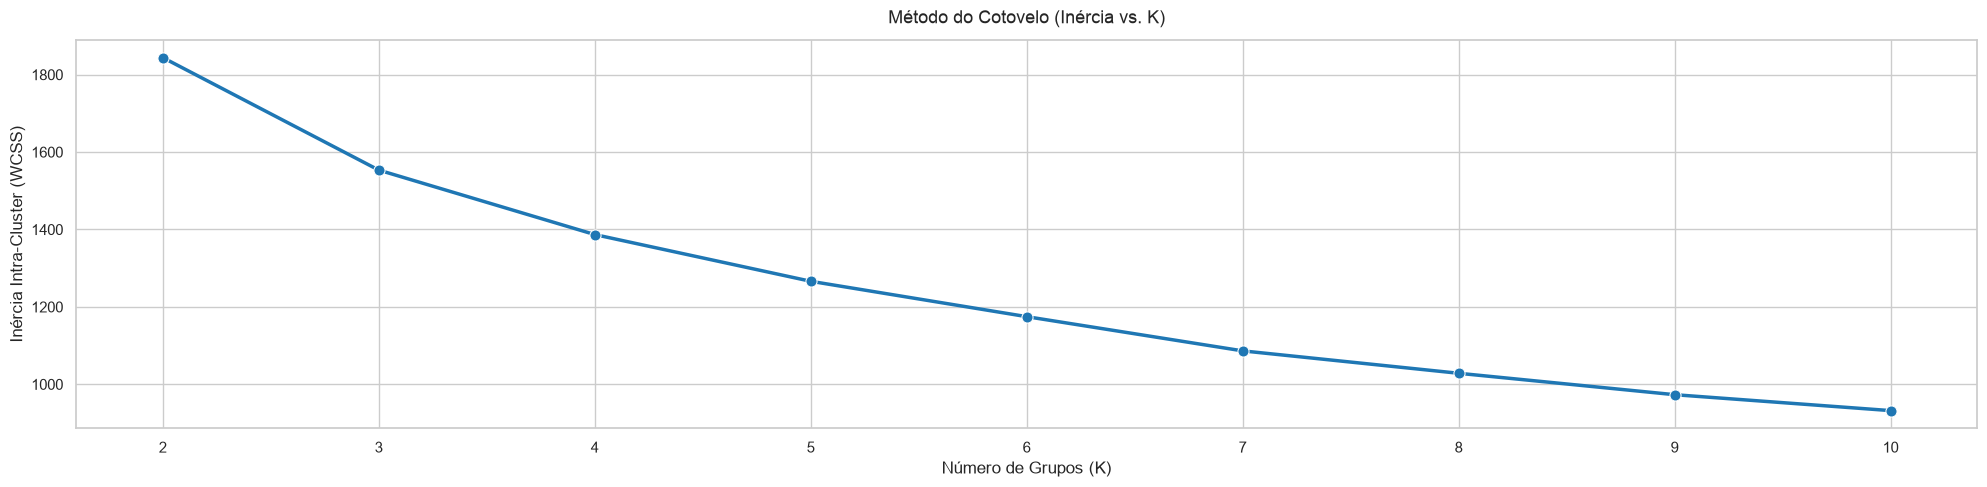

In [9]:
plt.figure(figsize=(20, 5))

sns.lineplot(
    x=k_range,
    y=inercia_valores,
    marker='o',
    markersize=8,
    linewidth=2.5,
    color='#1f77b4'
)
plt.title("Método do Cotovelo (Inércia vs. K)", fontsize=13, pad=12)
plt.xlabel("Número de Grupos (K)", fontsize=12)
plt.ylabel("Inércia Intra-Cluster (WCSS)", fontsize=12)
plt.xticks(k_range)

plt.tight_layout()
plt.show()

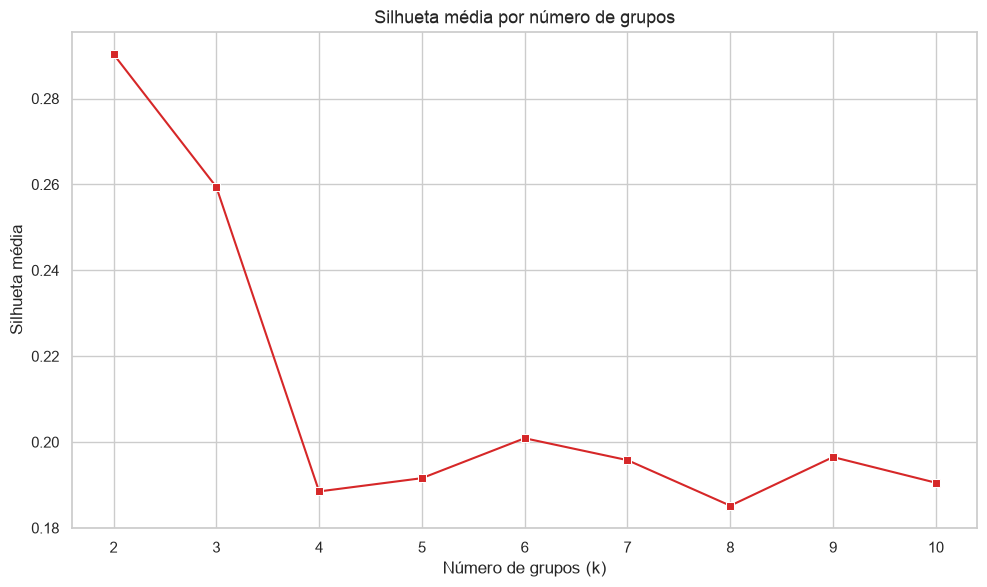

In [10]:
plt.figure(figsize=(10, 6))
sns.lineplot(x=k_range, y=silhueta_valores, marker='s', color='#d62728')
plt.title('Silhueta média por número de grupos')
plt.xlabel('Número de grupos (k)')
plt.ylabel('Silhueta média')
plt.xticks(k_range)
plt.tight_layout()
plt.show()


### Escolha de k = 2

| Critério | Evidência e interpretação |
|---|---|
| Silhueta | O maior valor testado foi **0,2903**, em k = 2; a separação ainda é parcial. |
| Cotovelo | A inércia cai de 1.844,06 para 1.553,42 entre k = 2 e k = 3, mas não há uma mudança de inclinação inequívoca. |
| Uso comercial | Dois perfis distinguem compras de frescos/congelados de mercearia/limpeza, permitindo ofertas por categoria. |

### Por que a inércia não basta?

Adicionar centroides não piora a **melhor solução possível**, pois a solução anterior ainda pode ser reproduzida. Assim, a inércia ótima não aumenta com k e favorece partições cada vez mais detalhadas. Execuções com mínimos locais podem apresentar oscilações.

No limite **k = 440**, cada cliente pode ser seu próprio centroide: a inércia seria zero, mas não haveria uma segmentação útil.

A silhueta varia de −1 a 1: valores altos indicam melhor separação, próximos de zero sugerem fronteiras pouco nítidas e negativos podem indicar atribuições inadequadas. O valor médio de **0,2903** favorece k = 2 entre as opções avaliadas, mas não caracteriza segmentos fortemente separados.


## Tarefa 4 — Inicialização e convergência

O k-Means pode convergir para mínimos locais diferentes. Com k = 2, executamos dez sementes para cada método, `random` e `k-means++`, usando `n_init=1`. A tabela registra a inércia final de cada execução.

In [11]:
inercia_random, inercia_kmeanspp = [], []
for semente in range(10):
    inercia_random.append(KMeans(n_clusters=2, init='random', n_init=1, random_state=semente).fit(X_scaled).inertia_)
    inercia_kmeanspp.append(KMeans(n_clusters=2, init='k-means++', n_init=1, random_state=semente).fit(X_scaled).inertia_)
df_init = pd.DataFrame({'Semente': range(10), 'Random': inercia_random, 'k-means++': inercia_kmeanspp})
display(df_init.round(2))
print(f'Desvio padrão — random: {np.std(inercia_random):.4f}')
print(f'Desvio padrão — k-means++: {np.std(inercia_kmeanspp):.4f}')


,Semente,Random,k-means++
0,0,1844.06,1844.13
1,1,1844.06,1844.06
2,2,1844.06,1844.06
3,3,1844.13,1844.06
4,4,1844.06,1844.13
5,5,1844.06,1844.06
6,6,1844.13,1844.13
7,7,1844.13,1844.13
8,8,1844.06,1844.06
9,9,1844.06,1844.06


Desvio padrão — random: 0.0289
Desvio padrão — k-means++: 0.0308


### Comparação das execuções

| Inicialização | Faixa de inércia final | Desvio padrão das dez execuções |
|---|---|---:|
| Random | 1.844,06–1.844,13 | 0,0289 |
| k-means++ | 1.844,06–1.844,13 | 0,0308 |

**Os métodos tiveram dispersões muito pequenas e semelhantes.** Neste experimento, k-means++ não apresentou vantagem observável.

### O que k-means++ procura melhorar?

Ele favorece novos centros distantes dos já escolhidos, usando a distância ao quadrado na amostragem. Isso reduz o risco de começar com centros concentrados na mesma região, mas não garante atingir o mínimo global em cada execução.

## Tarefa 5 — Perfis e validação externa

Revertemos a padronização e depois aplicamos `expm1` aos centroides. Eles voltam às unidades monetárias, mas não são médias aritméticas dos gastos brutos.

Comparamos os grupos com Channel e Region e projetamos os dados por PCA. Esses metadados não participaram do ajuste.

In [12]:
kmeans_final = KMeans(n_clusters=2, random_state=42, n_init=10)
df['Cluster'] = kmeans_final.fit_predict(X_scaled)

# Reversão dos centroides para a escala original de gastos
centroides_scaled = kmeans_final.cluster_centers_
centroides_log = scaler.inverse_transform(centroides_scaled)
centroides_original = np.expm1(centroides_log)

tabela_centroides = pd.DataFrame(
    centroides_original,
    columns=features_gasto,
    index=['Cluster 0 (Perfil Horeca / Restaurantes)', 'Cluster 1 (Perfil Varejo / Supermercados)']
).round(2)

display(tabela_centroides)

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster 0 (Perfil Horeca / Restaurantes),8580.59,1753.70,2274.38,2063.83,287.37,649.35
Cluster 1 (Perfil Varejo / Supermercados),4013.88,8061.57,12051.07,953.53,4035.60,1022.09


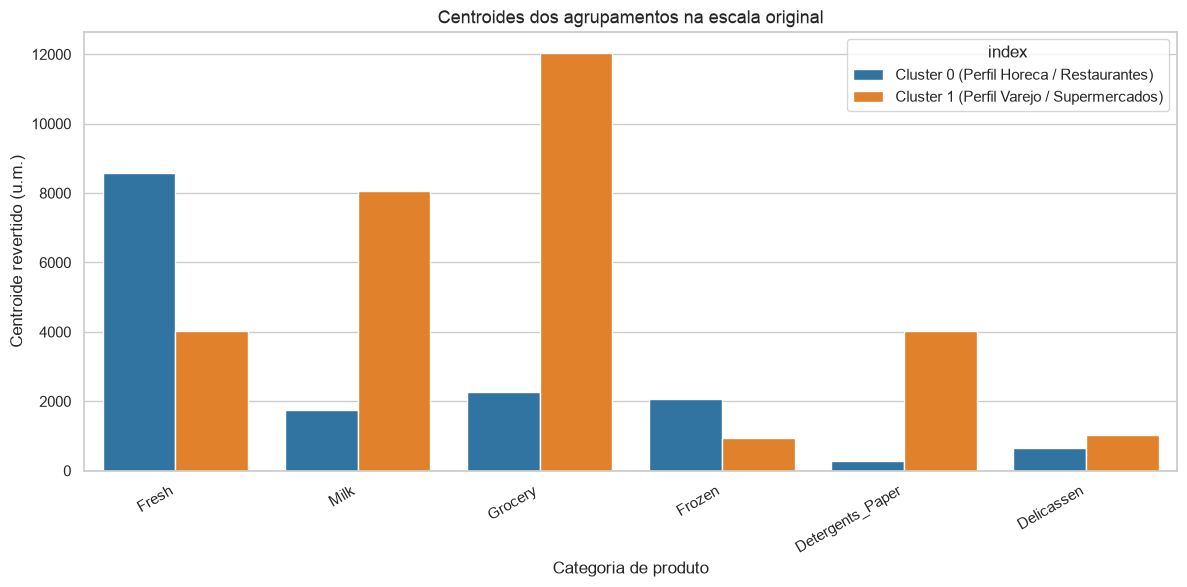

In [13]:
centroides_plot = tabela_centroides.reset_index().melt(
    id_vars='index', var_name='Categoria', value_name='Centroide revertido (u.m.)'
)
plt.figure(figsize=(12, 6))
sns.barplot(data=centroides_plot, x='Categoria', y='Centroide revertido (u.m.)',
            hue='index', palette=['#1f77b4', '#ff7f0e'])
plt.title('Centroides dos agrupamentos na escala original')
plt.xlabel('Categoria de produto')
plt.ylabel('Centroide revertido (u.m.)')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()


In [14]:
# Mapeamento descritivo dos canais e regiões
df['Channel_Desc'] = df['Channel'].map({1: 'Horeca (Hotéis/Restaurantes)', 2: 'Retail (Varejo)'})
df['Region_Desc'] = df['Region'].map({1: 'Lisboa', 2: 'Porto', 3: 'Outras Regiões'})

# Tabelas de Contingência
tabela_cruzada_canal = pd.crosstab(df['Channel_Desc'], df['Cluster'], margins=True)
tabela_cruzada_canal.columns = ['Cluster 0 (Restaurantes)', 'Cluster 1 (Varejo)', 'Total']
print("=== Tabela de Contingência: Canal vs. Cluster ===")
display(tabela_cruzada_canal)

tabela_cruzada_regiao = pd.crosstab(df['Region_Desc'], df['Cluster'], margins=True)
tabela_cruzada_regiao.columns = ['Cluster 0 (Restaurantes)', 'Cluster 1 (Varejo)', 'Total']
print("\n=== Tabela de Contingência: Região vs. Cluster ===")
display(tabela_cruzada_regiao)

ari_canal = adjusted_rand_score(df['Channel'], df['Cluster'])
ari_regiao = adjusted_rand_score(df['Region'], df['Cluster'])

print(f"\nÍndice Rand Ajustado (ARI) com Channel: {ari_canal:.4f}")
print(f"Índice Rand Ajustado (ARI) com Region:  {ari_regiao:.4f}")

=== Tabela de Contingência: Canal vs. Cluster ===


,Cluster 0 (Restaurantes),Cluster 1 (Varejo),Total
Channel_Desc,,,
Horeca (Hotéis/Restaurantes),244,54,298
Retail (Varejo),8,134,142
All,252,188,440



=== Tabela de Contingência: Região vs. Cluster ===


,Cluster 0 (Restaurantes),Cluster 1 (Varejo),Total
Region_Desc,,,
Lisboa,48,29,77
Outras Regiões,176,140,316
Porto,28,19,47
All,252,188,440



Índice Rand Ajustado (ARI) com Channel: 0.5135
Índice Rand Ajustado (ARI) com Region:  -0.0077


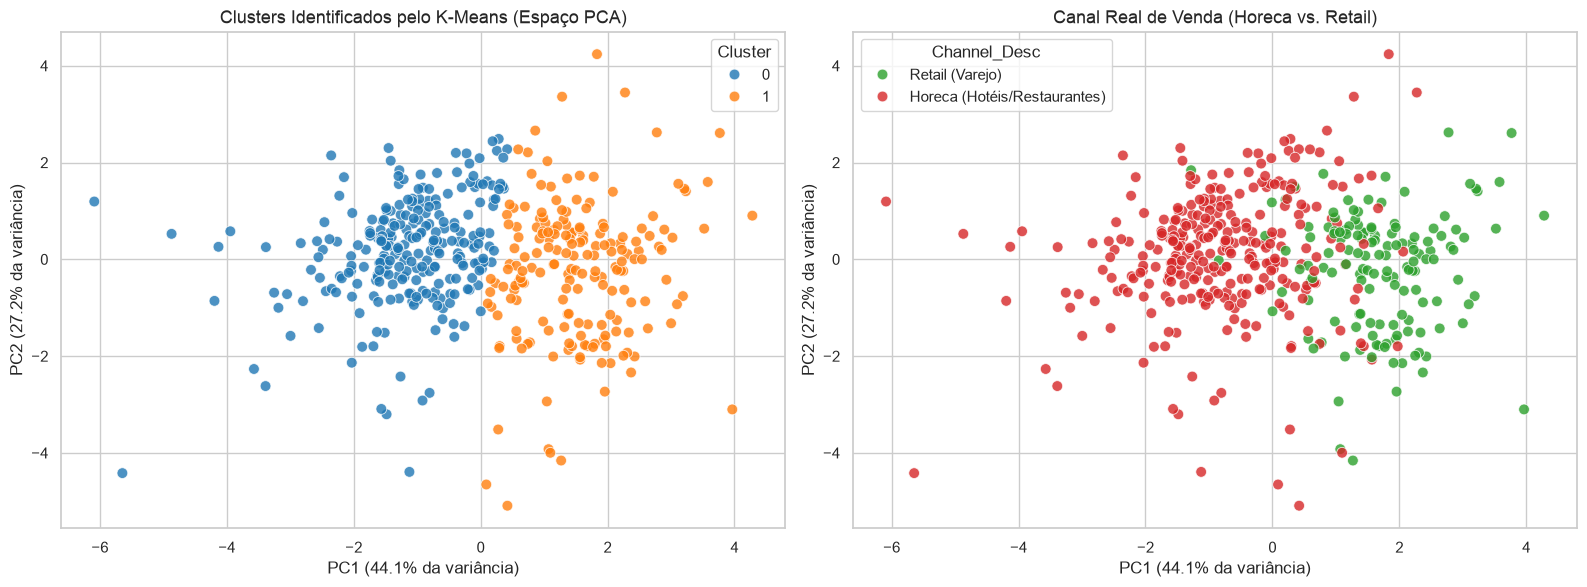

In [15]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

df['PCA1'] = X_pca[:, 0]
df['PCA2'] = X_pca[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Colorido por Cluster do K-Means
sns.scatterplot(
    data=df,
    x='PCA1',
    y='PCA2',
    hue='Cluster',
    palette=['#1f77b4', '#ff7f0e'],
    alpha=0.8,
    s=60,
    ax=axes[0]
)
axes[0].set_title("Clusters Identificados pelo K-Means (Espaço PCA)", fontsize=13)
axes[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% da variância)", fontsize=12)
axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% da variância)", fontsize=12)

# 2. Colorido pelo Canal Real de Venda
sns.scatterplot(
    data=df,
    x='PCA1',
    y='PCA2',
    hue='Channel_Desc',
    palette=['#2ca02c', '#d62728'],
    alpha=0.8,
    s=60,
    ax=axes[1]
)
axes[1].set_title("Canal Real de Venda (Horeca vs. Retail)", fontsize=13)
axes[1].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% da variância)", fontsize=12)
axes[1].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% da variância)", fontsize=12)

plt.tight_layout()
plt.show()

### Perfis comerciais

| Grupo | Clientes | Nome do perfil | Categorias de destaque |
|---|---:|---|---|
| 0 | 252 | **Frescos/congelados** | Fresh e Frozen |
| 1 | 188 | **Mercearia/limpeza** | Grocery, Detergents_Paper e Milk |

### O canal de venda foi reconstruído?

Parcialmente. O ARI com Channel foi **0,5135**, longe da concordância perfeita de 1.

- **Horeca:** 244 dos 298 clientes ficaram no grupo 0.
- **Retail:** 134 dos 142 clientes ficaram no grupo 1.

Fresh e Frozen são mais altos no perfil ligado a Horeca; Grocery, Detergents_Paper e Milk, no ligado a Retail. Os grupos representam padrões de gasto, não identificações perfeitas do canal.

### A região aparece nos grupos?

O ARI com Region foi −0,0077, próximo de zero. As tabelas de contingência mostram clientes de todas as regiões nos dois grupos; não há correspondência clara entre região e partição.

### Limitações observadas no PCA

A nuvem não forma duas esferas isoladas, há alongamento e proximidade entre os grupos. O k-Means favorece grupos compactos e tende a funcionar melhor com dispersões e tamanhos semelhantes, embora não imponha tamanhos iguais.
Além disso, pontos afastados da região mais densa permanecem visíveis. Como os centroides são médias, esses pontos podem deslocá-los mesmo após log1p.

As duas componentes exibidas retêm cerca de **71,3% da variância**. A projeção ajuda na interpretação, mas não descreve toda a geometria das seis categorias.

### Como utilizar os perfis

| Perfil | Aplicação comercial possível |
|---|---|
| Frescos/congelados | Direcionar ofertas dessas categorias e planejar reposição e transporte refrigerado conforme a demanda. |
| Mercearia/limpeza | Combinar ofertas de mercearia, laticínios e limpeza e ajustar o estoque dessas linhas. |

Os centroides descrevem um cliente típico no espaço transformado, não representam o gasto médio bruto nem o total de compras de cada grupo. Para dimensionar estoques, os volumes reais precisam ser consultados.

Em conclusão, os dois grupos fornecem uma segmentação inicial interpretável, com correspondência parcial ao canal de venda. Como há sobreposição e clientes atípicos, o perfil deve orientar ofertas, sem substituir a análise do histórico individual. A região não se reflete claramente nos grupos e precisa ser considerada separadamente no planejamento de rotas.
